<a href="https://colab.research.google.com/github/Kevin1077/SIH-2024/blob/main/data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "/content/drive/MyDrive/ICTAK/Classes/Data Preprocessing/beer-servings.csv"
df_bear = pd.read_csv(file_path)
print(df_bear.head())

   Unnamed: 0      country  beer_servings  spirit_servings  wine_servings  \
0           0  Afghanistan            0.0              0.0            0.0   
1           1      Albania           89.0            132.0           54.0   
2           2      Algeria           25.0              0.0           14.0   
3           3      Andorra          245.0            138.0          312.0   
4           4       Angola          217.0             57.0           45.0   

   total_litres_of_pure_alcohol continent  
0                           0.0      Asia  
1                           4.9    Europe  
2                           0.7    Africa  
3                          12.4    Europe  
4                           5.9    Africa  


EDA

In [ ]:
print(df_bear.shape)
print(df_bear.info())

(193, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Unnamed: 0                    193 non-null    int64  
 1   country                       193 non-null    object 
 2   beer_servings                 185 non-null    float64
 3   spirit_servings               185 non-null    float64
 4   wine_servings                 187 non-null    float64
 5   total_litres_of_pure_alcohol  192 non-null    float64
 6   continent                     193 non-null    object 
dtypes: float64(4), int64(1), object(2)
memory usage: 10.7+ KB
None


In [ ]:
print(df_bear.describe())

       Unnamed: 0  beer_servings  spirit_servings  wine_servings  \
count  193.000000     185.000000       185.000000     187.000000   
mean    96.000000     105.124324        83.221622      50.165775   
std     55.858452     100.524714        89.142958      80.358868   
min      0.000000       0.000000         0.000000       0.000000   
25%     48.000000      20.000000         4.000000       1.000000   
50%     96.000000      76.000000        60.000000       9.000000   
75%    144.000000     185.000000       132.000000      60.500000   
max    192.000000     376.000000       438.000000     370.000000   

       total_litres_of_pure_alcohol  
count                    192.000000  
mean                       4.741667  
std                        3.767654  
min                        0.000000  
25%                        1.300000  
50%                        4.250000  
75%                        7.200000  
max                       14.400000  


In [ ]:
print(df_bear["continent"].value_counts())

continent
Africa           53
Europe           45
Asia             44
North America    23
Oceania          16
South America    12
Name: count, dtype: int64


In [ ]:
df_bear.drop(columns = ['Unnamed: 0'], axis=1, inplace=True)

In [ ]:
num_cols = df_bear.select_dtypes(include=['number']).columns
cat_cols = df_bear.select_dtypes(include=['object']).columns
print(num_cols)

Index(['beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol'],
      dtype='object')


In [ ]:
print(cat_cols)

Index(['country', 'continent'], dtype='object')


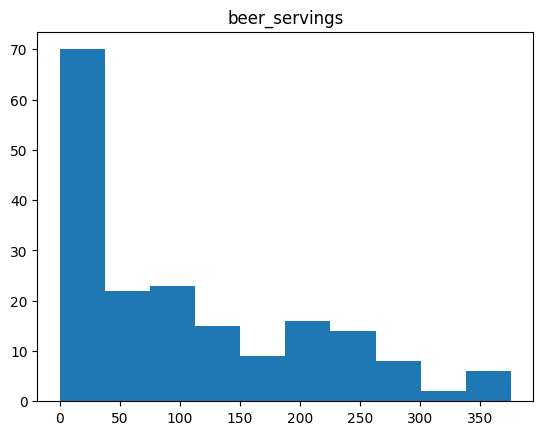

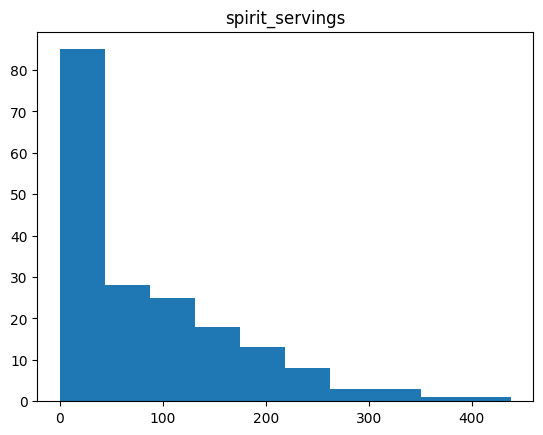

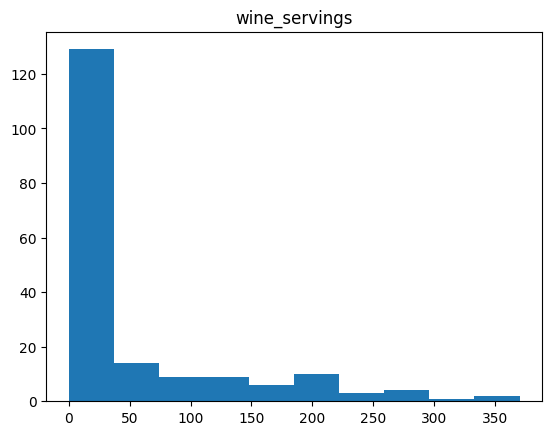

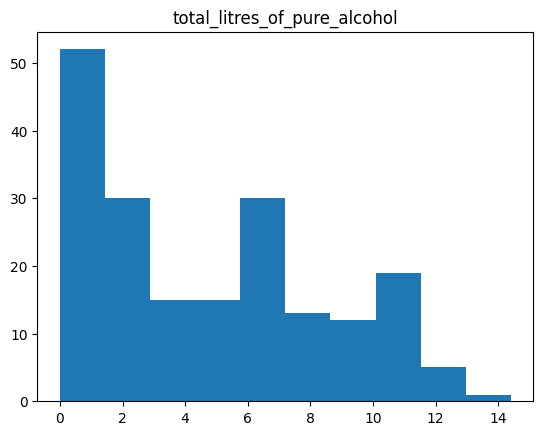

In [ ]:
#plotting histogram of all numerical columns
for col in num_cols:
  plt.hist(df_bear[col])
  plt.title(col)
  plt.show()


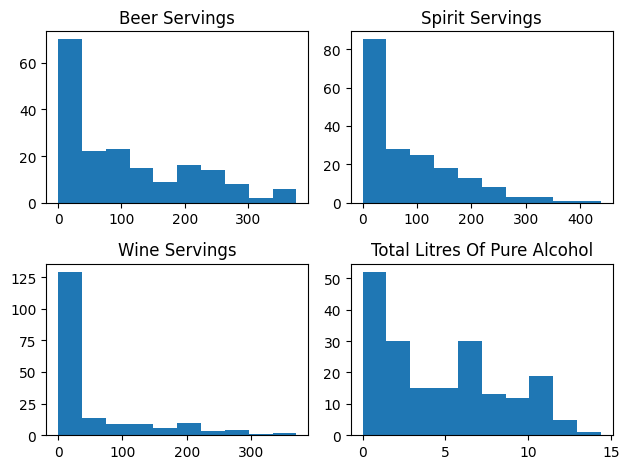

In [ ]:
#creating a subplot
for i, col in enumerate(num_cols, 1):
  plt.subplot(2, 2, i)
  plt.hist(df_bear[col])
  plt.title(col.replace("_"," ").title())

plt.tight_layout()
plt.show()

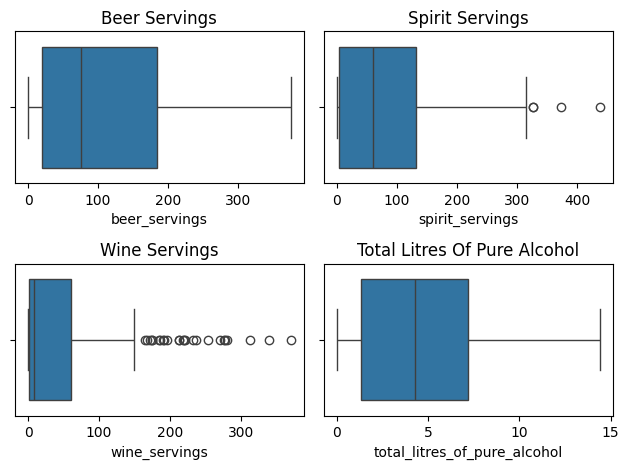

In [ ]:
for i, col in enumerate(num_cols, 1):
  plt.subplot(2, 2, i)
  sns.boxplot(data = df_bear, x=df_bear[col])
  plt.title(col.replace("_"," ").title())
plt.tight_layout()
plt.show()

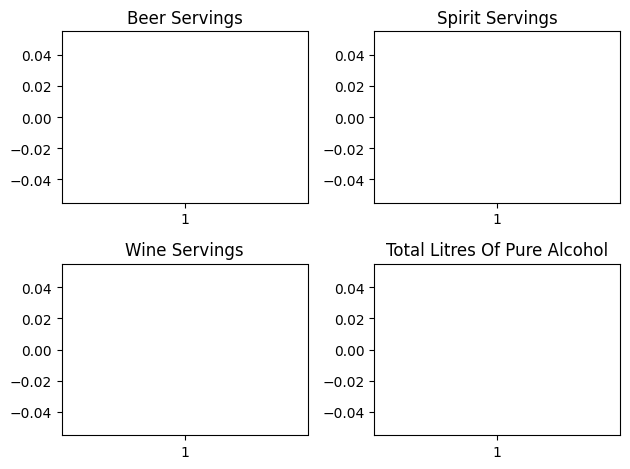

In [ ]:
for i, col in enumerate(num_cols, 1):
  plt.subplot(2, 2, i)
  plt.boxplot(data = df_bear, x=df_bear[col])
  plt.title(col.replace("_"," ").title())
plt.tight_layout()
plt.show()

All columns are skewed.


null value handling/ missing value handling


statergy use median to replace

#Data Preprocessing

##Data cleaning

####1) Null values handling

####Missing value handling

---



1.   
2.   List item



In [ ]:
print(df_bear.isna().sum())

country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64


In [ ]:
num_cols

Index(['beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol'],
      dtype='object')

In [ ]:
#replacing missing values
#df_bear["beer_servings"].fillna(df_bear["beer_servings"].median, inplace=True)
#print(df_bear.isna().sum())

In [ ]:
for col in num_cols:
  df_bear[col].fillna(df_bear[col].median(), inplace=True)
print(df_bear.isna().sum())

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64


/tmp/ipykernel_1529/3689392165.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_bear[col].fillna(df_bear[col].median(), inplace=True)


2. Outlier Handling

so outliers are values outside normal range.

so for understanding outliers we need to know Q1, Q2, Q3

Q1 is first quartile  25th percentile or median of lower half of dataset

Q3 is third quartile 75th percentile or median of upper half of dataset.

lower and upper boundary defines the minimum and maximum values that is specified by IQR(Q3 - Q1) and all values below lower boundary and above upper boundary are outliers.

In [ ]:
df_bear.shape

(193, 6)

In [ ]:
Q1 = df_bear[num_cols].quantile(0.25)
Q3 = df_bear[num_cols].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

#fetching outliers
outliers = ((df_bear[num_cols] > upper_limit) | (df_bear[num_cols] < lower_limit))

#remooving outliers
df_beer_without_outliers = df_bear[~outliers.any(axis=1)]

#df_beer_without_outliers = ((df_bear[num_cols] <= upper_limit) & (df_bear[num_cols] >= lower_limit))

#replacing outliers
df_bear[num_cols] = df_bear[num_cols].clip(lower = lower_limit, upper = upper_limit, axis = 1)


In [ ]:
df_beer_without_outliers.shape

(162, 6)

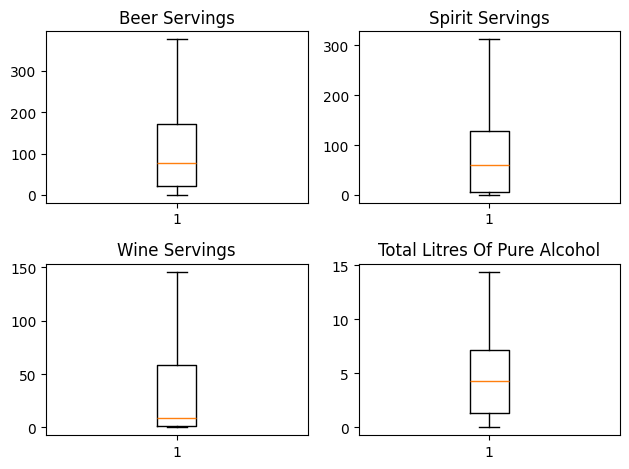

In [ ]:
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(df_bear[col])  # Fixed: pass df_bear[col] instead of df_bear
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

In [ ]:
Q1

,0.25
beer_servings,21.0
spirit_servings,5.0
wine_servings,1.0
total_litres_of_pure_alcohol,1.3


In [ ]:
Q3

,0.75
beer_servings,171.0
spirit_servings,128.0
wine_servings,59.0
total_litres_of_pure_alcohol,7.2


In [ ]:
IQR

,0
beer_servings,150.0
spirit_servings,123.0
wine_servings,58.0
total_litres_of_pure_alcohol,5.9


In [ ]:
outliers

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,True,False
4,False,False,False,False
...,...,...,...,...
188,False,False,False,False
189,False,False,False,False
190,False,False,False,False
191,False,False,False,False


Duplicate Remooval

In [ ]:
df_bear.duplicated().sum()

np.int64(0)

In [ ]:

df_bear.drop_duplicates(inplace=True)

In [ ]:
df_bear.duplicated().sum()

np.int64(0)

##Data Transformation

we need to identify target column and feature column

for categorical values if we have too many unique values in a column we cannot consider that column as a target column


we convert text to number, applicable only to categorical column

if categorical column is target column


1.   Label Encoding: sorts unique value alphebetically and assigns a number to each unique values
2.   Ordinal Encoding: we have to give the order in which the numbers have to be assigned to the unique values

if categorical column is the feature column



*   One hot encoding: we create dedicated column for each unique value in the categorical feature column.presence of the value is marked with '1' and absence is marked with '0'.








In [ ]:
#assuming continent is target column
df_bear["continent"].unique()

array(['Asia', 'Europe', 'Africa', 'North America', 'South America',
       'Oceania'], dtype=object)

In [ ]:
label_encoder = LabelEncoder()
df_bear["continent"] = label_encoder.fit_transform(df_bear["continent"])
df_bear.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.0,1
1,Albania,89.0,132.0,54.0,4.9,2
2,Algeria,25.0,0.0,14.0,0.7,0
3,Andorra,245.0,138.0,146.0,12.4,2
4,Angola,217.0,57.0,45.0,5.9,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()
encoder_data = encoder.fit_transform(df_bear[["continent"]])

#converting to panda dataframe

encoder_df = pd.DataFrame(
    encoder_data.toarray(),
    columns = encoder.get_feature_names_out(["continent"]),
    index = df_bear.index
)

encoder_df.head()

,continent_0,continent_1,continent_2,continent_3,continent_4,continent_5
0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
encoder_df2 = pd.get_dummies(df_bear, columns=["continent"], dtype=int)
encoder_df2

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent_0,continent_1,continent_2,continent_3,continent_4,continent_5
0,Afghanistan,0.0,0.0,0.0,0.0,0,1,0,0,0,0
1,Albania,89.0,132.0,54.0,4.9,0,0,1,0,0,0
2,Algeria,25.0,0.0,14.0,0.7,1,0,0,0,0,0
3,Andorra,245.0,138.0,146.0,12.4,0,0,1,0,0,0
4,Angola,217.0,57.0,45.0,5.9,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
188,Venezuela,76.0,100.0,3.0,7.7,0,0,0,0,0,1
189,Vietnam,111.0,2.0,1.0,2.0,0,1,0,0,0,0
190,Yemen,6.0,0.0,0.0,0.1,0,1,0,0,0,0
191,Zambia,32.0,19.0,4.0,2.5,1,0,0,0,0,0
